In [1]:
import sys
import os
sys.path.append(os.path.abspath('../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ucphm import *
from sklearn.preprocessing import OneHotEncoder
from sksurv.util import Surv
from sklearn.model_selection import StratifiedGroupKFold
from sksurv.metrics import (concordance_index_censored, integrated_brier_score)
from sksurv.linear_model import CoxPHSurvivalAnalysis
from scipy import stats
import seaborn as sns
from scipy.stats import skew
from scipy.stats import norm

KeyboardInterrupt: 

In [39]:
dataset = pd.read_excel('../BreastCareCond.xlsx')
data_code = pd.read_excel('../Codificação variaveis.xlsx')

In [40]:
#Defining the proposed has good treatment variables to use (the empty ones were removed)
treatment_variables = ['Radiotherapy (RT) performed', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 
                       'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
                        'Endocrine therapy performed', 'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
                        'Chemotherapy performed', 'Adjuvant chemotherapy', 'Adjuvant therapy with biological drugs']
len(treatment_variables)

13

In [41]:
#Separating the treatment variables into numerical and categorical
numerical_data, categorical_data = type_separation(data_code, treatment_variables)
len(numerical_data), len(categorical_data)

(3, 10)

In [42]:
change_to_numeric(dataset, numerical_data)
change_to_categorical(dataset, categorical_data)

Done
Done


In [43]:
numerical_descriptive_statistics(dataset, numerical_data)

,Counts,Mean,Median,Sd,Max,Min,25th,50th,75th
Conventional RT fraction,2981,3.120765,3.0,1.127527,24.0,2.0,3.0,3.0,3.0
Total administered dose,3008,40.807513,41.0,4.379699,70.0,5.0,41.0,41.0,41.0
Boost dose administered,2649,2.995092,3.0,0.599262,24.0,2.0,3.0,3.0,3.0


In [44]:
categorical_descriptive_statistics(dataset, categorical_data)

,Counts,Number of Classes,Top Class,Frequency of Top Class
Radiotherapy (RT) performed,3871,2,{0: 1},3229
Radiotherapy on chest wall,3870,2,{0: 1.0},3409
Radiotherapy on supraclavicular area,3870,2,{0: 0.0},2864
Radiotherapy on internal mammary chain,3870,2,{0: 0.0},3800
Endocrine therapy performed,3871,3,{0: 0},3189
State (if hormone therapy prescribed),3871,2,{0: 1},2954
Treatment in association with chemotherapy,3871,2,{0: 0},2476
Chemotherapy performed,3871,3,{0: 0},2530
Adjuvant chemotherapy,3871,3,{0: 0},3387
Adjuvant therapy with biological drugs,453,2,{0: 1.0},373


In [45]:
missing_values(dataset, numerical_data)

,Column,Missing Values,Percentage Missing
0,Conventional RT fraction,890,22.991475
1,Total administered dose,863,22.293981
2,Boost dose administered,1222,31.568070


In [46]:
missing_values(dataset, categorical_data)

,Column,Missing Values,Percentage Missing
0,Radiotherapy (RT) performed,0,0.000000
1,Radiotherapy on chest wall,1,0.025833
2,Radiotherapy on supraclavicular area,1,0.025833
3,Radiotherapy on internal mammary chain,1,0.025833
4,Endocrine therapy performed,0,0.000000
5,State (if hormone therapy prescribed),0,0.000000
6,Treatment in association with chemotherapy,0,0.000000
7,Chemotherapy performed,0,0.000000
8,Adjuvant chemotherapy,0,0.000000
9,Adjuvant therapy with biological drugs,3418,88.297598


So here I am seeing that the values in the Radiotherapy (RT) performed that are zero, meaning not done, are the ones that are missing from the other features

In [47]:
# rows where RT wasn't performed
rt_not_performed = dataset['Radiotherapy (RT) performed'] == 0

# should be NaN for dose/fraction in those rows -- checking
missing_check = dataset.loc[rt_not_performed, ['Conventional RT fraction', 'Total administered dose', 'Boost dose administered']].isna()

summary = missing_check.sum()
print("Number of missing values in each variable when RT was not performed:")
print(summary)

# sanity check for violations
non_missing_violations = dataset.loc[rt_not_performed & dataset[['Conventional RT fraction', 'Total administered dose', 'Boost dose administered']].notna().any(axis=1)]
print("Rows where RT was marked as not performed but dose/fraction values are present:")
print(non_missing_violations)


Number of missing values in each variable when RT was not performed:
Conventional RT fraction    642
Total administered dose     642
Boost dose administered     642
dtype: int64
Rows where RT was marked as not performed but dose/fraction values are present:
Empty DataFrame
Columns: [PERSON_ID, Number identifying the lesion in the patient, Age, Sex, Eligible from excusion, Side location of the lesion, Classification with respect to other lesions, Source of referral, Result of mammogram, Date of mammogram, Ultrasound scan, Date of ultrasound scan, MRI, Date or MRI, Cytological result, Core biopsy result, Type of invasion at CB, Date of CB , Istotype at CB, Grade at CB, Oestrogen receptor status at CB, Progesterone receptor status at CB, Proliferation activity (Ki67) at CB, Ki67 positive cells (%) at CB, Her2 overexpression (with immunohystochemistry) at CB, FISH hybridization at CB, Clinical examination, Disease extent, Tumour size by imaging or clinical examination, T by imaging or clin

Checking for the correlation between these ones

In [48]:
dataset[['Conventional RT fraction', 'Total administered dose', 'Boost dose administered']].corr()

,Conventional RT fraction,Total administered dose,Boost dose administered
Conventional RT fraction,1.000000,-0.686967,0.974025
Total administered dose,-0.686967,1.000000,-0.719451
Boost dose administered,0.974025,-0.719451,1.000000


So I will also fill with zeros the numerical data

In [49]:
replace_missing_values(dataset, numerical_data, 0)

Done


In [50]:
# Just because this one is different
def simplify_variable(dataset, variables, max_value):
    for variable in variables:
        dataset[variable] = dataset[variable].apply(
            lambda x: str(x) if x < max_value else '>6'
        )
    return dataset

In [51]:
one_hot_variables_2 = ['Conventional RT fraction', 'Boost dose administered']
dataset = simplify_variable(dataset, one_hot_variables_2, 4)
change_to_categorical(dataset, one_hot_variables_2)

Done


Removing the first patient since it had several treatment values missing.

In [52]:
dataset.drop(index=0, inplace=True)
dataset.reset_index(inplace=True, drop=True)
replace_missing_values(dataset, categorical_data, 0)

Done


The missing values were replaced with 0 since it made sense
For these variables the first is if the treatment was done, and the second was when it was not done by patient refusal. Regarding the bio variable the first column is if it was done and second is if it was with Trastuzumab (0) or other drugs (1)

In [28]:
one_hot_variables = ['Endocrine therapy performed','Adjuvant chemotherapy', 'Chemotherapy performed']
bio_variable = 'Adjuvant therapy with biological drugs'
df = encode(dataset, one_hot_variables, 'first')
df_2 = encode(df, one_hot_variables_2, None)
one_hot_dataset = encode_bio_therapy(df_2, bio_variable)
one_hot_dataset

,PERSON_ID,Number identifying the lesion in the patient,Age,Sex,Eligible from excusion,Side location of the lesion,Classification with respect to other lesions,Source of referral,Result of mammogram,Date of mammogram,...,Conventional RT fraction_0.0,Conventional RT fraction_2.0,Conventional RT fraction_3.0,Conventional RT fraction_>6,Boost dose administered_0.0,Boost dose administered_2.0,Boost dose administered_3.0,Boost dose administered_>6,Adjuvant therapy with bio drugs,Trastuzumab or other drugs
0,2,1,52.0,F,0.0,L,1.0,2,3.0,2012-05-16,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0
1,3,1,43.0,F,0.0,L,1.0,2,NaN,NaT,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0
2,4,1,46.0,F,3.0,L,1.0,1,NaN,NaT,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0,0.0
3,5,1,39.0,F,0.0,R,1.0,2,NaN,NaT,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0,0.0
4,6,1,52.0,F,0.0,L,1.0,1,NaN,NaT,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3865,3516,1,65.0,F,NaN,L,1.0,2,5.0,2023-02-19,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0
3866,3517,1,49.0,F,NaN,R,1.0,2,5.0,2023-02-09,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0
3867,3518,1,66.0,F,NaN,R,1.0,1,5.0,2023-03-10,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0
3868,3519,1,74.0,F,0.0,L,1.0,1,5.0,2023-02-28,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0


In [29]:
date_columns = ['Date of CB ', 'Date of 1st breast operation', 'Date of intervention on sentinel lymph node', 
                'Date of intervention (axilla)']
date_dataset = date_of_diagnosis(one_hot_dataset, date_columns)
date_dataset

,PERSON_ID,Number identifying the lesion in the patient,Age,Sex,Eligible from excusion,Side location of the lesion,Classification with respect to other lesions,Source of referral,Result of mammogram,Date of mammogram,...,Conventional RT fraction_2.0,Conventional RT fraction_3.0,Conventional RT fraction_>6,Boost dose administered_0.0,Boost dose administered_2.0,Boost dose administered_3.0,Boost dose administered_>6,Adjuvant therapy with bio drugs,Trastuzumab or other drugs,Date of diagnosis
0,2,1,52.0,F,0.0,L,1.0,2,3.0,2012-05-16,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2014-10-08
1,3,1,43.0,F,0.0,L,1.0,2,NaN,NaT,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-02
2,4,1,46.0,F,3.0,L,1.0,1,NaN,NaT,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0,0.0,2017-12-14
3,5,1,39.0,F,0.0,R,1.0,2,NaN,NaT,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-12-13
4,6,1,52.0,F,0.0,L,1.0,1,NaN,NaT,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3865,3516,1,65.0,F,NaN,L,1.0,2,5.0,2023-02-19,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-20
3866,3517,1,49.0,F,NaN,R,1.0,2,5.0,2023-02-09,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-14
3867,3518,1,66.0,F,NaN,R,1.0,1,5.0,2023-03-10,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2023-03-06
3868,3519,1,74.0,F,0.0,L,1.0,1,5.0,2023-02-28,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-23


The date of 1st regional recurrence corresponds to exactly that if Regional LN recurrence is zero, if not it corresponds to date of follow up or date of death (doesn't matter the difference).

In [30]:
relevant_dates = ['Date of diagnosis', 'Date of 1st regional recurrence']
date_dataset = remove_zeros_na(date_dataset, relevant_dates)
date_dataset = format_date(date_dataset, relevant_dates)
date_dataset

,PERSON_ID,Number identifying the lesion in the patient,Age,Sex,Eligible from excusion,Side location of the lesion,Classification with respect to other lesions,Source of referral,Result of mammogram,Date of mammogram,...,Conventional RT fraction_2.0,Conventional RT fraction_3.0,Conventional RT fraction_>6,Boost dose administered_0.0,Boost dose administered_2.0,Boost dose administered_3.0,Boost dose administered_>6,Adjuvant therapy with bio drugs,Trastuzumab or other drugs,Date of diagnosis
0,2,1,52.0,F,0.0,L,1.0,2,3.0,2012-05-16,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2014-10-08
1,3,1,43.0,F,0.0,L,1.0,2,NaN,NaT,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-02
2,4,1,46.0,F,3.0,L,1.0,1,NaN,NaT,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0,0.0,2017-12-14
3,5,1,39.0,F,0.0,R,1.0,2,NaN,NaT,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-12-13
4,6,1,52.0,F,0.0,L,1.0,1,NaN,NaT,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3407,3515,1,51.0,F,NaN,L,1.0,1,5.0,2023-02-27,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-28
3408,3516,1,65.0,F,NaN,L,1.0,2,5.0,2023-02-19,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-20
3409,3517,1,49.0,F,NaN,R,1.0,2,5.0,2023-02-09,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-14
3410,3518,1,66.0,F,NaN,R,1.0,1,5.0,2023-03-10,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2023-03-06


In [31]:
date_dataset = survival_days(date_dataset, ['Date of diagnosis'], ['Date of 1st regional recurrence'])
date_dataset

,PERSON_ID,Number identifying the lesion in the patient,Age,Sex,Eligible from excusion,Side location of the lesion,Classification with respect to other lesions,Source of referral,Result of mammogram,Date of mammogram,...,Conventional RT fraction_3.0,Conventional RT fraction_>6,Boost dose administered_0.0,Boost dose administered_2.0,Boost dose administered_3.0,Boost dose administered_>6,Adjuvant therapy with bio drugs,Trastuzumab or other drugs,Date of diagnosis,Survival days
0,2,1,52.0,F,0.0,L,1.0,2,3.0,2012-05-16,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2014-10-08,1882.0
1,3,1,43.0,F,0.0,L,1.0,2,NaN,NaT,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-02,3982.0
2,4,1,46.0,F,3.0,L,1.0,1,NaN,NaT,...,0.0,1.0,1.0,0.0,0.0,0.0,0,0.0,2017-12-14,1012.0
3,5,1,39.0,F,0.0,R,1.0,2,NaN,NaT,...,1.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-12-13,630.0
4,6,1,52.0,F,0.0,L,1.0,1,NaN,NaT,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-29,2714.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3407,3515,1,51.0,F,NaN,L,1.0,1,5.0,2023-02-27,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-28,265.0
3408,3516,1,65.0,F,NaN,L,1.0,2,5.0,2023-02-19,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-20,197.0
3409,3517,1,49.0,F,NaN,R,1.0,2,5.0,2023-02-09,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-14,313.0
3410,3518,1,66.0,F,NaN,R,1.0,1,5.0,2023-03-10,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2023-03-06,298.0


In [32]:
date_dataset = tte_negative_patients(date_dataset)
date_dataset

,PERSON_ID,Number identifying the lesion in the patient,Age,Sex,Eligible from excusion,Side location of the lesion,Classification with respect to other lesions,Source of referral,Result of mammogram,Date of mammogram,...,Conventional RT fraction_3.0,Conventional RT fraction_>6,Boost dose administered_0.0,Boost dose administered_2.0,Boost dose administered_3.0,Boost dose administered_>6,Adjuvant therapy with bio drugs,Trastuzumab or other drugs,Date of diagnosis,Survival days
0,2,1,52.0,F,0.0,L,1.0,2,3.0,2012-05-16,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2014-10-08,1882.0
1,3,1,43.0,F,0.0,L,1.0,2,NaN,NaT,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-02,3982.0
2,4,1,46.0,F,3.0,L,1.0,1,NaN,NaT,...,0.0,1.0,1.0,0.0,0.0,0.0,0,0.0,2017-12-14,1012.0
3,5,1,39.0,F,0.0,R,1.0,2,NaN,NaT,...,1.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-12-13,630.0
4,6,1,52.0,F,0.0,L,1.0,1,NaN,NaT,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-29,2714.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3407,3515,1,51.0,F,NaN,L,1.0,1,5.0,2023-02-27,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-28,265.0
3408,3516,1,65.0,F,NaN,L,1.0,2,5.0,2023-02-19,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-20,197.0
3409,3517,1,49.0,F,NaN,R,1.0,2,5.0,2023-02-09,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-14,313.0
3410,3518,1,66.0,F,NaN,R,1.0,1,5.0,2023-03-10,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2023-03-06,298.0


In [33]:
date_dataset = filter_EBC(date_dataset)
date_dataset.reset_index(drop=True, inplace=True)
date_dataset

,PERSON_ID,Number identifying the lesion in the patient,Age,Sex,Eligible from excusion,Side location of the lesion,Classification with respect to other lesions,Source of referral,Result of mammogram,Date of mammogram,...,Conventional RT fraction_3.0,Conventional RT fraction_>6,Boost dose administered_0.0,Boost dose administered_2.0,Boost dose administered_3.0,Boost dose administered_>6,Adjuvant therapy with bio drugs,Trastuzumab or other drugs,Date of diagnosis,Survival days
0,2,1,52.0,F,0.0,L,1.0,2,3.0,2012-05-16,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2014-10-08,1882.0
1,3,1,43.0,F,0.0,L,1.0,2,NaN,NaT,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-02,3982.0
2,4,1,46.0,F,3.0,L,1.0,1,NaN,NaT,...,0.0,1.0,1.0,0.0,0.0,0.0,0,0.0,2017-12-14,1012.0
3,5,1,39.0,F,0.0,R,1.0,2,NaN,NaT,...,1.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-12-13,630.0
4,7,1,57.0,F,0.0,L,1.0,1,NaN,NaT,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2011-11-21,3679.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3230,3515,1,51.0,F,NaN,L,1.0,1,5.0,2023-02-27,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-28,265.0
3231,3516,1,65.0,F,NaN,L,1.0,2,5.0,2023-02-19,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-20,197.0
3232,3517,1,49.0,F,NaN,R,1.0,2,5.0,2023-02-09,...,1.0,0.0,0.0,0.0,1.0,0.0,0,0.0,2023-02-14,313.0
3233,3518,1,66.0,F,NaN,R,1.0,1,5.0,2023-03-10,...,0.0,0.0,1.0,0.0,0.0,0.0,0,0.0,2023-03-06,298.0


Creation of the survival dataset with only the interessing columns

In [34]:
feature_columns = ['Endocrine therapy performed_1', 'Endocrine therapy performed_2', 'Adjuvant chemotherapy_1', 'Adjuvant chemotherapy_2', 
                  'Chemotherapy performed_1', 'Chemotherapy performed_2', 'Adjuvant therapy with bio drugs', 'Trastuzumab or other drugs', 
                  'Conventional RT fraction_2.0', 'Conventional RT fraction_3.0', 'Conventional RT fraction_>6', 'Conventional RT fraction_0.0', 
                  'Boost dose administered_2.0', 'Boost dose administered_3.0', 'Boost dose administered_>6',	'Boost dose administered_0.0']
feature_columns = feature_columns + categorical_data + numerical_data
bio_variable = ['Adjuvant therapy with biological drugs']
one_hot_variables = one_hot_variables + one_hot_variables_2 + bio_variable
feature_columns = [col for col in feature_columns if col not in one_hot_variables]
data_columns = ['PERSON_ID', 'Date of diagnosis', 'Regional LN recurrence', 'Date of 1st regional recurrence', 'Survival days']
selected_columns = data_columns + feature_columns

In [35]:
survival_dataset = date_dataset[selected_columns]
survival_dataset

,PERSON_ID,Date of diagnosis,Regional LN recurrence,Date of 1st regional recurrence,Survival days,Endocrine therapy performed_1,Endocrine therapy performed_2,Adjuvant chemotherapy_1,Adjuvant chemotherapy_2,Chemotherapy performed_1,...,Boost dose administered_3.0,Boost dose administered_>6,Boost dose administered_0.0,Radiotherapy (RT) performed,Radiotherapy on chest wall,Radiotherapy on supraclavicular area,Radiotherapy on internal mammary chain,State (if hormone therapy prescribed),Treatment in association with chemotherapy,Total administered dose
0,2,2014-10-08,0.0,2019-12-03,1882.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1,1.0,0.0,0.0,1,0,41.0
1,3,2011-11-02,0.0,2022-09-27,3982.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1,1.0,1.0,0.0,1,1,0.0
2,4,2017-12-14,0.0,2020-09-21,1012.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1,1.0,0.0,0.0,0,0,32.0
3,5,2011-12-13,0.0,2013-09-03,630.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1,1.0,0.0,0.0,1,1,43.0
4,7,2011-11-21,0.0,2021-12-17,3679.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0,1.0,0.0,0.0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3230,3515,2023-02-28,0.0,2023-11-20,265.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1,1.0,0.0,0.0,1,0,41.0
3231,3516,2023-02-20,0.0,2023-09-05,197.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1,1.0,0.0,0.0,1,0,41.0
3232,3517,2023-02-14,0.0,2023-12-24,313.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1,1.0,0.0,0.0,1,0,41.0
3233,3518,2023-03-06,0.0,2023-12-29,298.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0,1.0,0.0,0.0,0,0,0.0


In [36]:
missing_values(survival_dataset, selected_columns)

,Column,Missing Values,Percentage Missing
0,PERSON_ID,0,0.0
1,Date of diagnosis,0,0.0
2,Regional LN recurrence,0,0.0
3,Date of 1st regional recurrence,0,0.0
4,Survival days,0,0.0
5,Endocrine therapy performed_1,0,0.0
6,Endocrine therapy performed_2,0,0.0
7,Adjuvant chemotherapy_1,0,0.0
8,Adjuvant chemotherapy_2,0,0.0
9,Chemotherapy performed_1,0,0.0


In [37]:
target = Surv.from_arrays(survival_dataset['Regional LN recurrence'], survival_dataset['Survival days'])
data_x = survival_dataset[feature_columns]
data_y = target
groups = survival_dataset['PERSON_ID']

In [167]:
univariate_results = univariate_cox_analysis(data_x, data_y, groups, 4)
univariate_results

Starting univariate analysis of 23 features...
Using 4-fold stratified group cross-validation
------------------------------------------------------------
[1/23] Analyzing: Endocrine therapy performed_1
    C-index: 0.6548 ± 0.0676
    Integrated Brier score: 0.0880 ± 0.0711
    HR: 2.9043 (95% CI: 1.8546–4.5481)
[2/23] Analyzing: Endocrine therapy performed_2
    C-index: 0.5025 ± 0.0016
    Integrated Brier score: 0.0765 ± 0.0682
    HR: 0.0000 (95% CI: 0.0000–0.0000)
[3/23] Analyzing: Adjuvant chemotherapy_1
    C-index: 0.5613 ± 0.0644
    Integrated Brier score: 0.0862 ± 0.0743
    HR: 1.5348 (95% CI: 1.0031–2.3482)
[4/23] Analyzing: Adjuvant chemotherapy_2
    C-index: 0.5005 ± 0.0003
    Integrated Brier score: 0.0765 ± 0.0682
    HR: 0.0000 (95% CI: 0.0000–0.0000)
[5/23] Analyzing: Chemotherapy performed_1
    C-index: 0.4407 ± 0.0664
    Integrated Brier score: 0.0738 ± 0.0642
    HR: 1.3383 (95% CI: 0.8032–2.2298)
[6/23] Analyzing: Chemotherapy performed_2
    C-index: 0.5007

,Feature,C_Index_Mean,C_Index_Std,Integrated_Brier_Score,Brier_Score_Std,Coefficient_Mean,Coefficient_Std,Hazard_Ratio,HR_95_CI_Lower,HR_95_CI_Upper,N_Successful_Folds
0,Endocrine therapy performed_1,0.654833,0.067590,0.088033,0.071079,1.066192,0.228833,2.904298e+00,1.854617e+00,4.548080e+00,4
1,Endocrine therapy performed_2,0.502538,0.001560,0.076530,0.068207,-14.510720,0.503686,4.989697e-07,1.859208e-07,1.339123e-06,4
2,Adjuvant chemotherapy_1,0.561297,0.064374,0.086212,0.074285,0.428392,0.216965,1.534788e+00,1.003146e+00,2.348187e+00,4
3,Adjuvant chemotherapy_2,0.500494,0.000342,0.076505,0.068220,-12.752091,0.433034,2.896257e-06,1.239456e-06,6.767731e-06,4
4,Chemotherapy performed_1,0.440656,0.066421,0.073785,0.064164,0.291363,0.260484,1.338251e+00,8.031726e-01,2.229802e+00,4
5,Chemotherapy performed_2,0.500739,0.000584,0.076505,0.068220,-13.002280,0.000452,2.255181e-06,2.253184e-06,2.257180e-06,4
6,Adjuvant therapy with bio drugs,0.497665,0.062821,0.077174,0.069616,-0.352505,0.316711,7.029248e-01,3.778495e-01,1.307672e+00,4
7,Trastuzumab or other drugs,0.477855,0.026122,0.076525,0.068220,-2.995714,6.945916,5.000091e-02,6.116383e-08,4.087532e+04,4
8,Conventional RT fraction_2.0,0.465216,0.048094,0.079007,0.068090,0.017950,0.559839,1.018112e+00,3.398219e-01,3.050283e+00,4
9,Conventional RT fraction_3.0,0.649060,0.119810,0.078531,0.067069,-1.131766,0.301202,3.224634e-01,1.786866e-01,5.819274e-01,4


In [168]:
univariate_results.to_csv('ucphm_pvalue.csv')

In [2]:
# univariate_results = pd.read_csv('ucphm.csv')

In [8]:
# I have very low data of these
highlight_features = ['Endocrine therapy performed_2', 'Adjuvant chemotherapy_2', 'Chemotherapy performed_2', 'Radiotherapy on internal mammary chain', 'Boost dose administered_>6']
# in the hazard ration these are giving a very high error not sure why
new_uni = univariate_results[
    ~univariate_results['Feature'].isin(['Conventional RT fraction_>6', 'Trastuzumab or other drugs'])
]

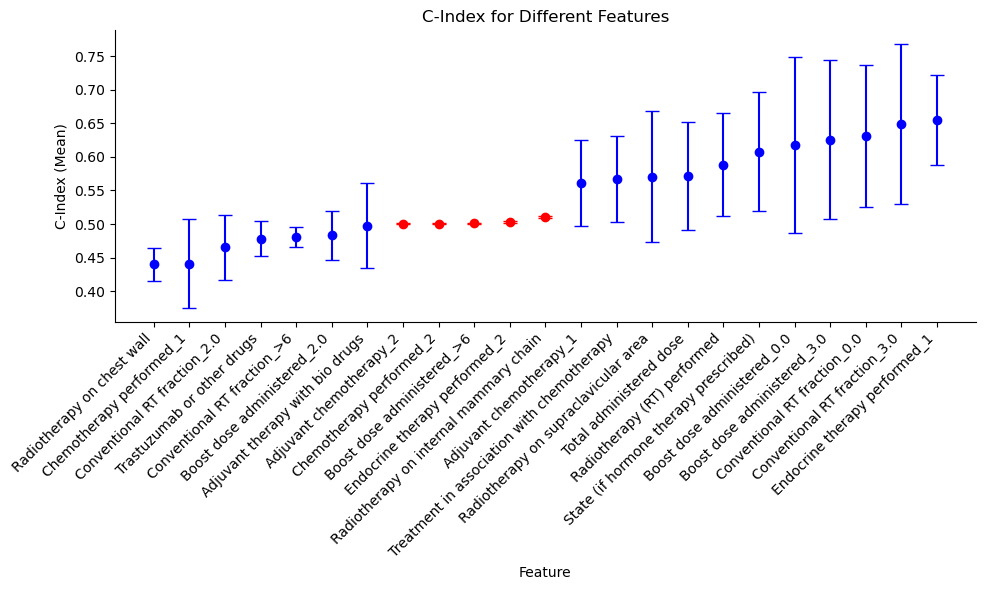

In [171]:
plot_cindex(univariate_results, 'ci_ucphm.png', highlight_features=highlight_features, highlight_color='red', default_color='blue')

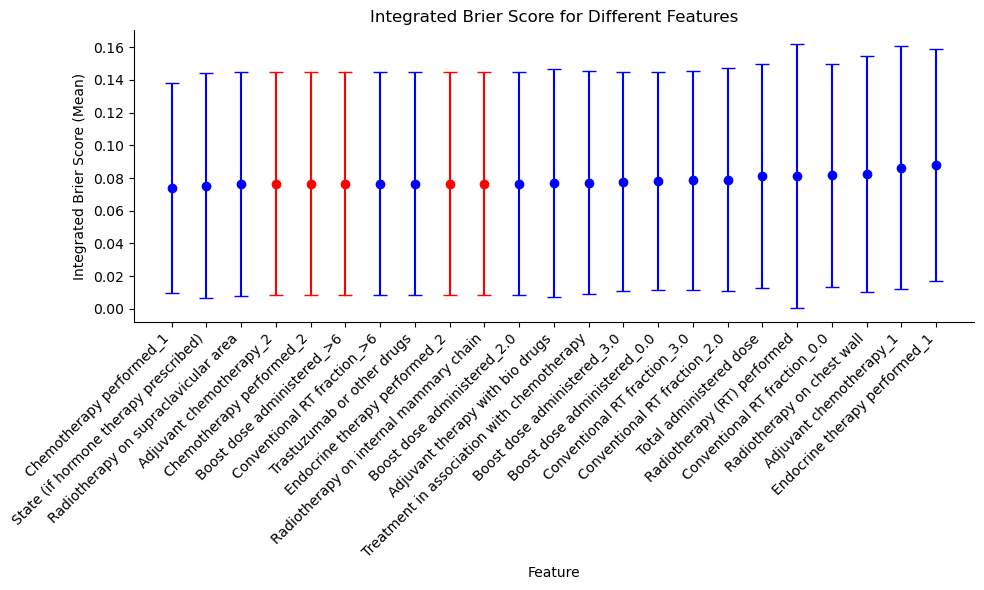

In [173]:
plot_brier(univariate_results, 'brier_ucphm.png', highlight_features=highlight_features, highlight_color='red', default_color='blue')

In [14]:
non_significant_features = univariate_results[univariate_results['P_Value_of_HR'] >= 0.05]
non_significant_features = non_significant_features['Feature'].to_list()
highlight_features = highlight_features + non_significant_features

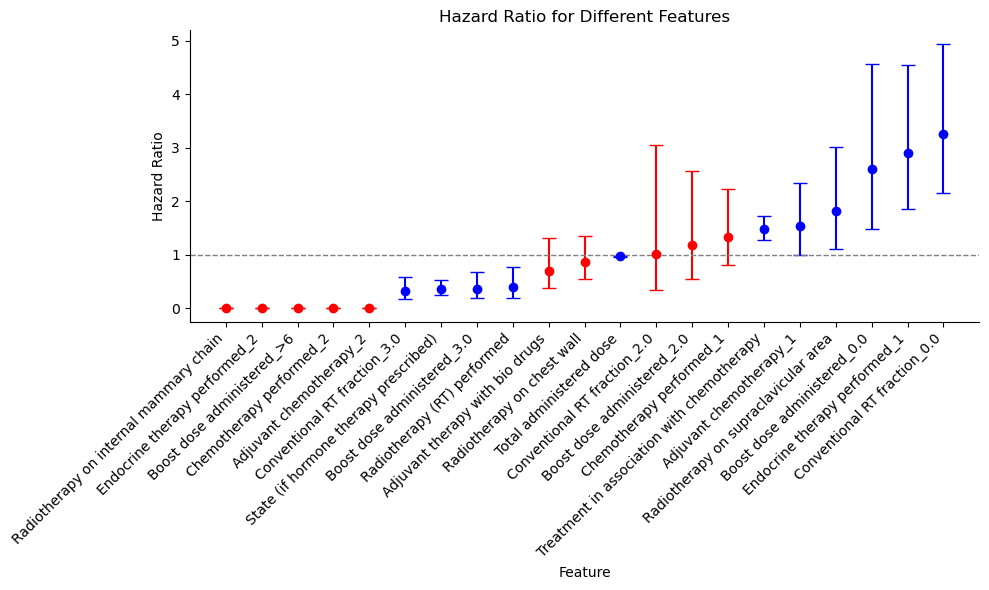

In [19]:
plot_hazard(new_uni, 'hr_ucphm.png', highlight_features=highlight_features, highlight_color='red', default_color='blue')

In [2]:
import pandas as pd
univariate_results = pd.read_csv('ucphm.csv')
mean_val = univariate_results.iloc[:, 2].mean()
std_val = univariate_results.iloc[:, 2].std()
print("Mean:", mean_val)
print("Std:", std_val)
num_significant = (univariate_results['P_Value_of_HR'] < 0.05).sum()
print("Number of significant features:", num_significant)
print("Total number of features:", len(univariate_results))

Mean: 0.5411873289857391
Std: 0.06795318499331889
Number of significant features: 18
Total number of features: 23
